In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [7]:
df=pd.read_csv('sales_data.csv')
df

,Order_ID,Date,Region,State,Category,Product,Quantity,Sales,Profit
0,ORD-2024-00381,2024-01-04,Asia Pacific,Seoul,Technology,Tablet,1,1740.96,470.08
1,ORD-2025-00773,2024-01-04,North America,New York,Technology,Monitor,3,3675.08,907.42
2,ORD-2025-00901,2024-01-04,North America,Florida,Appliances,Coffee Maker,8,2657.64,513.85
3,ORD-2025-00846,2024-01-04,North America,Florida,Technology,Smartphone,8,8451.91,1820.99
4,ORD-2024-00465,2024-01-05,Europe,Bavaria,Office Supplies,Notebook,2,135.73,39.07
...,...,...,...,...,...,...,...,...,...
1195,ORD-2025-00810,2025-12-29,North America,Ontario,Office Supplies,Printer Paper,5,206.67,55.18
1196,ORD-2025-00691,2025-12-29,North America,Florida,Furniture,Conference Table,4,752.98,164.97
1197,ORD-2024-00401,2025-12-30,North America,Texas,Furniture,Office Chair,11,8229.87,682.35
1198,ORD-2025-01169,2025-12-30,North America,California,Office Supplies,Pen Set,7,596.32,191.08


In [8]:
df.head()

,Order_ID,Date,Region,State,Category,Product,Quantity,Sales,Profit
0,ORD-2024-00381,2024-01-04,Asia Pacific,Seoul,Technology,Tablet,1,1740.96,470.08
1,ORD-2025-00773,2024-01-04,North America,New York,Technology,Monitor,3,3675.08,907.42
2,ORD-2025-00901,2024-01-04,North America,Florida,Appliances,Coffee Maker,8,2657.64,513.85
3,ORD-2025-00846,2024-01-04,North America,Florida,Technology,Smartphone,8,8451.91,1820.99
4,ORD-2024-00465,2024-01-05,Europe,Bavaria,Office Supplies,Notebook,2,135.73,39.07


In [9]:
df.tail()

,Order_ID,Date,Region,State,Category,Product,Quantity,Sales,Profit
1195,ORD-2025-00810,2025-12-29,North America,Ontario,Office Supplies,Printer Paper,5,206.67,55.18
1196,ORD-2025-00691,2025-12-29,North America,Florida,Furniture,Conference Table,4,752.98,164.97
1197,ORD-2024-00401,2025-12-30,North America,Texas,Furniture,Office Chair,11,8229.87,682.35
1198,ORD-2025-01169,2025-12-30,North America,California,Office Supplies,Pen Set,7,596.32,191.08
1199,ORD-2025-00820,2025-12-31,North America,Florida,Technology,Smartphone,2,2404.35,463.74


In [10]:
df.shape

(1200, 9)

In [11]:
df.columns

Index(['Order_ID', 'Date', 'Region', 'State', 'Category', 'Product',
       'Quantity', 'Sales', 'Profit'],
      dtype='str')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  1200 non-null   str    
 1   Date      1200 non-null   str    
 2   Region    1200 non-null   str    
 3   State     1200 non-null   str    
 4   Category  1200 non-null   str    
 5   Product   1200 non-null   str    
 6   Quantity  1200 non-null   int64  
 7   Sales     1200 non-null   float64
 8   Profit    1200 non-null   float64
dtypes: float64(2), int64(1), str(6)
memory usage: 160.0 KB


In [13]:
df.dtypes

Order_ID        str
Date            str
Region          str
State           str
Category        str
Product         str
Quantity      int64
Sales       float64
Profit      float64
dtype: object

In [14]:
df.describe()

,Quantity,Sales,Profit
count,1200.000000,1200.000000,1200.000000
mean,6.115000,3614.656892,594.163008
std,3.224196,3833.218389,855.069521
min,1.000000,10.680000,-4032.110000
25%,3.000000,646.242500,101.085000
50%,6.000000,2186.175000,307.735000
75%,9.000000,5357.025000,900.250000
max,11.000000,18483.150000,4793.620000


In [15]:
df.isnull().sum()

Order_ID    0
Date        0
Region      0
State       0
Category    0
Product     0
Quantity    0
Sales       0
Profit      0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.nunique()

Order_ID    1200
Date         579
Region         5
State         25
Category       4
Product       20
Quantity      11
Sales       1198
Profit      1192
dtype: int64

In [19]:
df["Category"].value_counts()

Category
Technology         473
Office Supplies    283
Furniture          282
Appliances         162
Name: count, dtype: int64

In [20]:
df["Region"].value_counts()

Region
North America           374
Europe                  301
Asia Pacific            254
Latin America           146
Middle East & Africa    125
Name: count, dtype: int64

In [21]:
df["Product"].value_counts().head(10)

Product
Laptop             105
Wireless Router    101
Smartphone         100
Tablet              92
Monitor             75
Notebook            73
Office Chair        61
Desk                59
Bookshelf           57
Stapler             56
Name: count, dtype: int64

In [22]:
print("Total Sales:", df["Sales"].sum())
print("Total Profit:", df["Profit"].sum())

Total Sales: 4337588.2700000005
Total Profit: 712995.6100000001


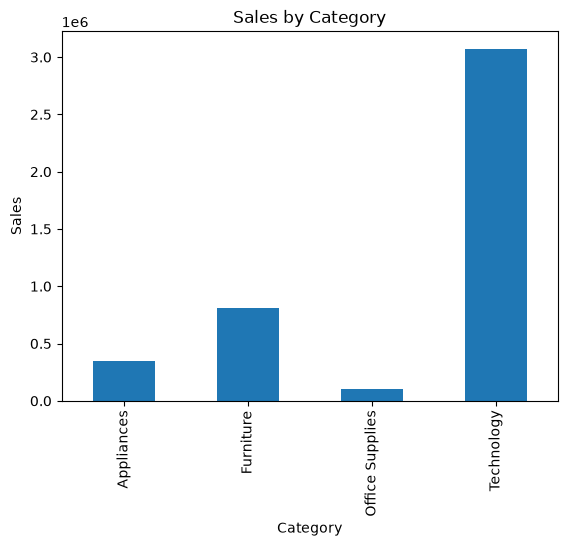

In [23]:
category_sales = df.groupby("Category")["Sales"].sum()

category_sales.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.show()

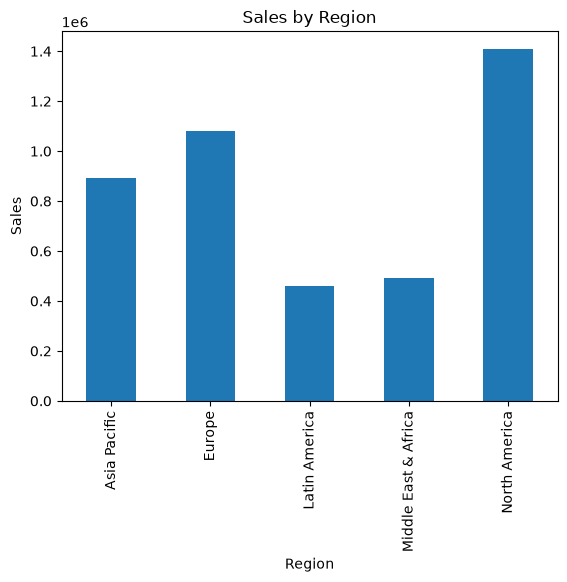

In [24]:
region_sales = df.groupby("Region")["Sales"].sum()

region_sales.plot(kind="bar")
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.show()

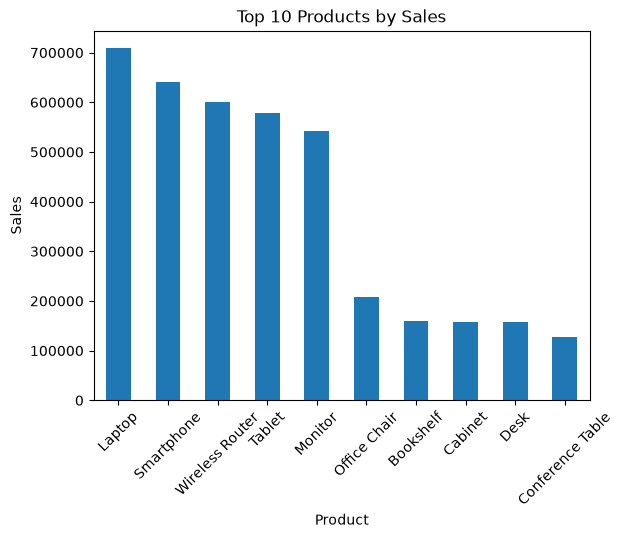

In [25]:
top_products = df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)

top_products.plot(kind="bar")
plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

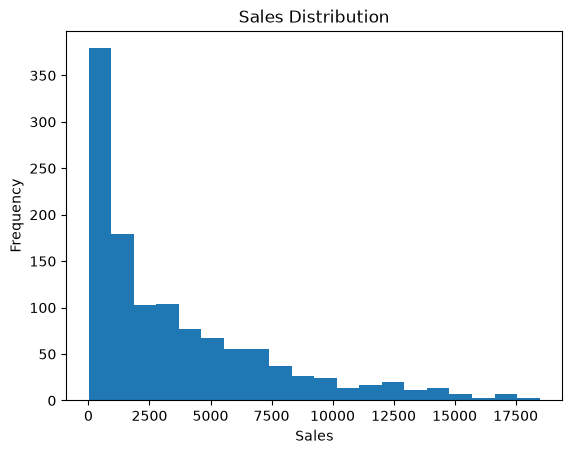

In [26]:
plt.hist(df["Sales"], bins=20)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

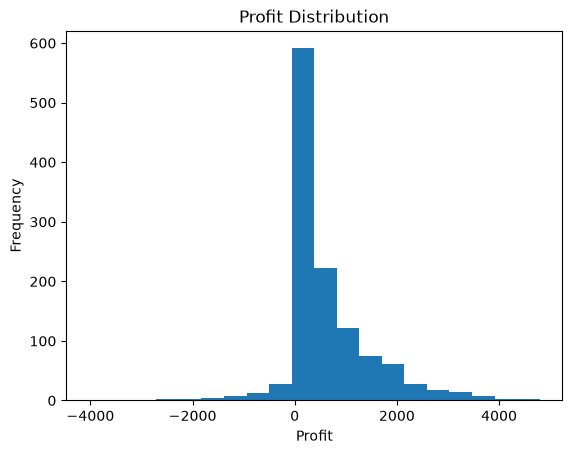

In [27]:
plt.hist(df["Profit"], bins=20)
plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

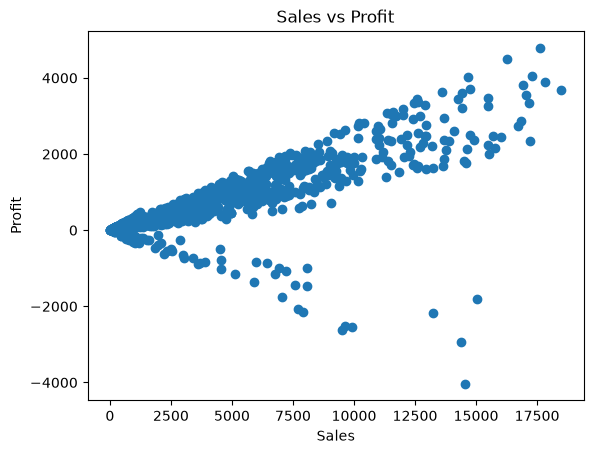

In [28]:
plt.scatter(df["Sales"], df["Profit"])
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

In [29]:
df[["Quantity", "Sales", "Profit"]].corr()

,Quantity,Sales,Profit
Quantity,1.000000,0.513910,0.394007
Sales,0.513910,1.000000,0.761333
Profit,0.394007,0.761333,1.000000
